<div style="width: 100%; max-width: 900px; box-sizing: border-box; background: linear-gradient(160deg, #0f2e22 0%, #122c1f 100%); border: 1.5px solid #10b981; border-radius: 18px; padding: 26px 24px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; box-shadow: 0 14px 40px rgba(0, 0, 0, 0.8); margin: 20px auto; position: relative; overflow: hidden;">
<div style="position: absolute; top: 0; left: 0; right: 0; height: 4px; background: linear-gradient(90deg, #10b981, #f59e0b, #10b981);"></div>

<div style="display: flex; align-items: center; gap: 16px; margin-bottom: 18px;">
<div style="flex-shrink: 0; width: 60px; height: 60px; border-radius: 14px; background: linear-gradient(135deg, #10b981, #059669); display: flex; align-items: center; justify-content: center; box-shadow: 0 6px 18px rgba(16, 185, 129, 0.4);">
<svg width="32" height="32" viewBox="0 0 24 24" fill="none" stroke="#ffffff" stroke-width="2" stroke-linecap="round" stroke-linejoin="round">
<path d="M4 7h16M4 12h16M4 17h10"/>
<circle cx="20" cy="17" r="2"/>
</svg>
</div>
<div style="flex: 1;">
<div style="display: inline-block; background: rgba(16, 185, 129, 0.12); border: 1px solid rgba(16, 185, 129, 0.45); border-radius: 20px; padding: 3px 12px; margin-bottom: 6px;">
<span style="color: #6ee7b7; font-size: 11px; font-weight: 800; letter-spacing: 2.5px; text-transform: uppercase;">Part 2 &bull; LSTM &bull; Step 01</span>
</div>
<h2 style="color: #ffffff; font-size: 22px; font-weight: 800; letter-spacing: 1px; text-transform: uppercase; margin: 0 0 4px 0;">Text Preprocessing</h2>
<p style="color: #94a3b8; font-size: 12.5px; font-weight: 600; margin: 0;">Clean &bull; Tokenize &bull; Pad Sequences</p>
</div>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">01.1 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Load &amp; Inspect IMDB Dataset</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">01.2 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Clean Text (Remove HTML, Lowercase)</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">01.3 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Tokenization &amp; Vocabulary</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">01.4 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Pad Sequences to Fixed Length</span>
</div>

</div>

In [24]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc


# Set seed for reproducibility
RANDOM_STATE = 42
tf.random.set_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

In [2]:
# Load the IMDB dataset (50,000 movie reviews)
# Update this path to match your local file location
df = pd.read_csv(r"C:\Users\AHSAN GHANI\Documents\6Month Intership program\Frist Month\pandas_tip&trick\Data set\movie review\IMDB Dataset.csv")

# Quick inspection
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nClass distribution:")
print(df['sentiment'].value_counts())
df.head()

Shape: (50000, 2)

Columns: ['review', 'sentiment']

Class distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [15]:


# ---- 2. Clean text ----
def clean_text(text):
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'http\S+', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = text.lower()
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_review'] = df['review'].apply(clean_text)

# ---- 3. Tokenize ----
VOCAB_SIZE = 10000
MAX_LEN    = 200

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(df['clean_review'])
sequences = tokenizer.texts_to_sequences(df['clean_review'])

# ---- 4. Pad sequences ----
X = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')
y = (df['sentiment'] == 'positive').astype(int).values

# ---- 5. Train/val split ----
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train.shape, "| X_val:", X_val.shape)
print("y_train:", y_train.shape, "| y_val:", y_val.shape)

X_train: (40000, 200) | X_val: (10000, 200)
y_train: (40000,) | y_val: (10000,)


In [16]:
# Configuration for tokenizer
VOCAB_SIZE   = 10000    # keep top 10,000 most frequent words
MAX_LEN      = 200      # every review will be padded/truncated to 200 tokens

# Build tokenizer and fit on cleaned reviews
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(df['clean_review'])

# Convert reviews to integer sequences
sequences = tokenizer.texts_to_sequences(df['clean_review'])

# Check one example
print("Original :", df['clean_review'][0][:100])
print("\nSequence :", sequences[0][:20])
print("\nVocabulary size:", len(tokenizer.word_index))

Original : one of the other reviewers has mentioned that after watching just oz episode you ll be hooked they a

Sequence : [29, 5, 2, 78, 2038, 47, 1052, 12, 101, 150, 42, 3057, 395, 21, 230, 30, 3173, 33, 26, 205]

Vocabulary size: 99342


In [17]:
# Pad all sequences to the same length (MAX_LEN)
X = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')

# Encode target labels: positive=1, negative=0
y = (df['sentiment'] == 'positive').astype(int).values

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFirst padded sequence:\n", X[0][:30])
print("\nLabel distribution:", np.bincount(y))

X shape: (50000, 200)
y shape: (50000,)

First padded sequence:
 [  29    5    2   78 2038   47 1052   12  101  150   42 3057  395   21
  230   30 3173   33   26  205   15   11    7  614   48  593   18   69
    2   89]

Label distribution: [25000 25000]


<div style="width: 100%; max-width: 900px; box-sizing: border-box; background: linear-gradient(160deg, #0f2e22 0%, #122c1f 100%); border: 1.5px solid #10b981; border-radius: 18px; padding: 26px 24px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; box-shadow: 0 14px 40px rgba(0, 0, 0, 0.8); margin: 20px auto; position: relative; overflow: hidden;">
<div style="position: absolute; top: 0; left: 0; right: 0; height: 4px; background: linear-gradient(90deg, #10b981, #f59e0b, #10b981);"></div>

<div style="display: flex; align-items: center; gap: 16px; margin-bottom: 18px;">
<div style="flex-shrink: 0; width: 60px; height: 60px; border-radius: 14px; background: linear-gradient(135deg, #10b981, #059669); display: flex; align-items: center; justify-content: center; box-shadow: 0 6px 18px rgba(16, 185, 129, 0.4);">
<svg width="32" height="32" viewBox="0 0 24 24" fill="none" stroke="#ffffff" stroke-width="2" stroke-linecap="round" stroke-linejoin="round">
<path d="M4 7h16M4 12h16M4 17h10"/>
<circle cx="20" cy="17" r="2"/>
</svg>
</div>
<div style="flex: 1;">
<div style="display: inline-block; background: rgba(16, 185, 129, 0.12); border: 1px solid rgba(16, 185, 129, 0.45); border-radius: 20px; padding: 3px 12px; margin-bottom: 6px;">
<span style="color: #6ee7b7; font-size: 11px; font-weight: 800; letter-spacing: 2.5px; text-transform: uppercase;">Part 2 &bull; LSTM &bull; Step 02</span>
</div>
<h2 style="color: #ffffff; font-size: 22px; font-weight: 800; letter-spacing: 1px; text-transform: uppercase; margin: 0 0 4px 0;">Build LSTM Model</h2>
<p style="color: #94a3b8; font-size: 12.5px; font-weight: 600; margin: 0;">Embedding &bull; LSTM &bull; Dense</p>
</div>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">02.1 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Embedding Layer</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">02.2 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">LSTM Layer</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">02.3 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Dense Output Layer</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">02.4 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Compile the Model</span>
</div>

</div>

In [18]:
# Build an LSTM model for binary sentiment classification
model = Sequential([

    # Embedding: learns word vectors from the 10,000-word vocabulary
    Embedding(input_dim=VOCAB_SIZE, output_dim=64, input_length=MAX_LEN),

    # Bidirectional LSTM: reads the sequence forward and backward
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.4),

    # Dense hidden layer
    Dense(32, activation='relu'),
    Dropout(0.3),

    # Output layer: single neuron with sigmoid for binary classification
    Dense(1, activation='sigmoid')
])

model.summary()

c:\Users\AHSAN GHANI\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [19]:
# Compile with Adam optimizer and binary crossentropy loss
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

<div style="width: 100%; max-width: 900px; box-sizing: border-box; background: linear-gradient(160deg, #0f2e22 0%, #122c1f 100%); border: 1.5px solid #10b981; border-radius: 18px; padding: 26px 24px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; box-shadow: 0 14px 40px rgba(0, 0, 0, 0.8); margin: 20px auto; position: relative; overflow: hidden;">
<div style="position: absolute; top: 0; left: 0; right: 0; height: 4px; background: linear-gradient(90deg, #10b981, #f59e0b, #10b981);"></div>

<div style="display: flex; align-items: center; gap: 16px; margin-bottom: 18px;">
<div style="flex-shrink: 0; width: 60px; height: 60px; border-radius: 14px; background: linear-gradient(135deg, #10b981, #059669); display: flex; align-items: center; justify-content: center; box-shadow: 0 6px 18px rgba(16, 185, 129, 0.4);">
<svg width="32" height="32" viewBox="0 0 24 24" fill="none" stroke="#ffffff" stroke-width="2" stroke-linecap="round" stroke-linejoin="round">
<polyline points="22 12 18 12 15 21 9 3 6 12 2 12"/>
</svg>
</div>
<div style="flex: 1;">
<div style="display: inline-block; background: rgba(16, 185, 129, 0.12); border: 1px solid rgba(16, 185, 129, 0.45); border-radius: 20px; padding: 3px 12px; margin-bottom: 6px;">
<span style="color: #6ee7b7; font-size: 11px; font-weight: 800; letter-spacing: 2.5px; text-transform: uppercase;">Part 2 &bull; LSTM &bull; Step 03</span>
</div>
<h2 style="color: #ffffff; font-size: 22px; font-weight: 800; letter-spacing: 1px; text-transform: uppercase; margin: 0 0 4px 0;">Model Training</h2>
<p style="color: #94a3b8; font-size: 12.5px; font-weight: 600; margin: 0;">Train with Validation &bull; Early Stopping</p>
</div>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">03.1 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Add Early Stopping Callback</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">03.2 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Train with Validation Data</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">03.3 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Plot Accuracy &amp; Loss Curves</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">03.4 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Save Best Model &amp; Summary</span>
</div>

</div>

In [20]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Stop training when validation loss stops improving
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True,
    verbose=1
)

# Save the best model during training
checkpoint = ModelCheckpoint(
    filepath='best_lstm_model.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

In [21]:
# Train the LSTM model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    callbacks=[early_stop, checkpoint],
    verbose=1
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step - accuracy: 0.7552 - loss: 0.4798
Epoch 1: val_loss improved from None to 0.32051, saving model to best_lstm_model.keras

Epoch 1: finished saving model to best_lstm_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 156s 473ms/step - accuracy: 0.7552 - loss: 0.4798 - val_accuracy: 0.8653 - val_loss: 0.3205
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms/step - accuracy: 0.8825 - loss: 0.3000
Epoch 2: val_loss did not improve from 0.32051
313/313 ━━━━━━━━━━━━━━━━━━━━ 161s 514ms/step - accuracy: 0.8825 - loss: 0.3000 - val_accuracy: 0.8572 - val_loss: 0.3292
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 493ms/step - accuracy: 0.9053 - loss: 0.2514
Epoch 3: val_loss did not improve from 0.32051
313/313 ━━━━━━━━━━━━━━━━━━━━ 162s 517ms/step - accuracy: 0.9053 - loss: 0.2514 - val_accuracy: 0.8223 - val_loss: 0.3881
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.


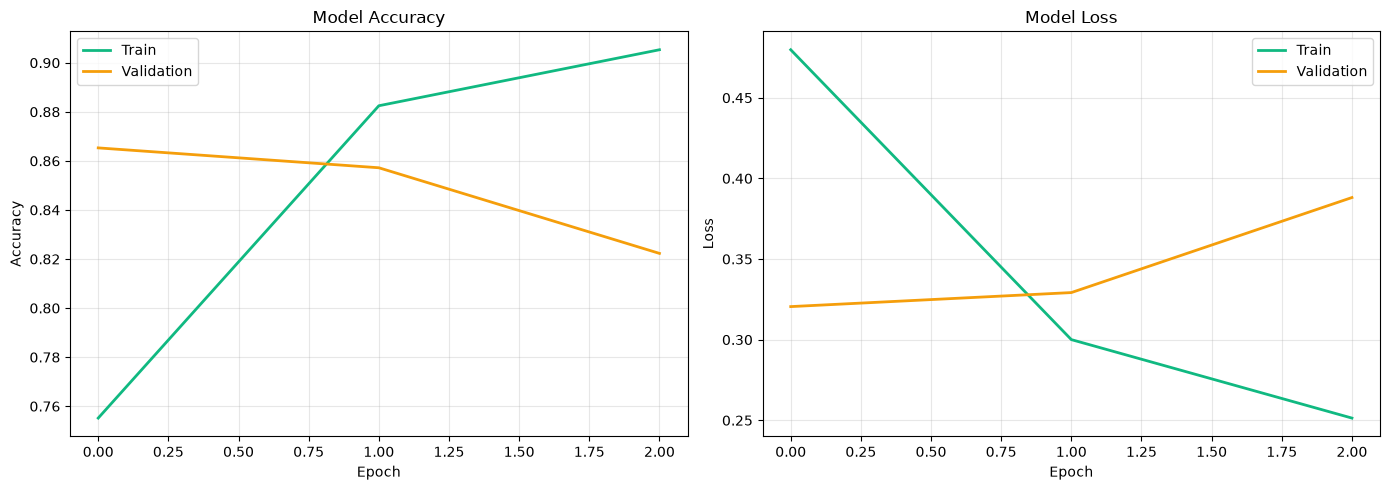

In [22]:
# Visualize training vs validation performance
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curves
ax[0].plot(history.history['accuracy'],     label='Train',      color='#10b981', linewidth=2)
ax[0].plot(history.history['val_accuracy'], label='Validation', color='#f59e0b', linewidth=2)
ax[0].set_title('Model Accuracy')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Accuracy')
ax[0].legend()
ax[0].grid(alpha=0.3)

# Loss curves
ax[1].plot(history.history['loss'],     label='Train',      color='#10b981', linewidth=2)
ax[1].plot(history.history['val_loss'], label='Validation', color='#f59e0b', linewidth=2)
ax[1].set_title('Model Loss')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Loss')
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
# Load the best model saved by ModelCheckpoint
best_model = tf.keras.models.load_model('best_lstm_model.keras')

# Print final training summary
print(f"Total epochs trained    : {len(history.history['loss'])}")
print(f"Best training accuracy  : {max(history.history['accuracy']):.4f}")
print(f"Best validation accuracy: {max(history.history['val_accuracy']):.4f}")
print(f"Best validation loss    : {min(history.history['val_loss']):.4f}")

Total epochs trained    : 3
Best training accuracy  : 0.9053
Best validation accuracy: 0.8653
Best validation loss    : 0.3205


<div style="width: 100%; max-width: 900px; box-sizing: border-box; background: linear-gradient(160deg, #0f2e22 0%, #122c1f 100%); border: 1.5px solid #10b981; border-radius: 18px; padding: 26px 24px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; box-shadow: 0 14px 40px rgba(0, 0, 0, 0.8); margin: 20px auto; position: relative; overflow: hidden;">
<div style="position: absolute; top: 0; left: 0; right: 0; height: 4px; background: linear-gradient(90deg, #10b981, #f59e0b, #10b981);"></div>

<div style="display: flex; align-items: center; gap: 16px; margin-bottom: 18px;">
<div style="flex-shrink: 0; width: 60px; height: 60px; border-radius: 14px; background: linear-gradient(135deg, #10b981, #059669); display: flex; align-items: center; justify-content: center; box-shadow: 0 6px 18px rgba(16, 185, 129, 0.4);">
<svg width="32" height="32" viewBox="0 0 24 24" fill="none" stroke="#ffffff" stroke-width="2" stroke-linecap="round" stroke-linejoin="round">
<path d="M22 11.08V12a10 10 0 1 1-5.93-9.14"/>
<polyline points="22 4 12 14.01 9 11.01"/>
</svg>
</div>
<div style="flex: 1;">
<div style="display: inline-block; background: rgba(16, 185, 129, 0.12); border: 1px solid rgba(16, 185, 129, 0.45); border-radius: 20px; padding: 3px 12px; margin-bottom: 6px;">
<span style="color: #6ee7b7; font-size: 11px; font-weight: 800; letter-spacing: 2.5px; text-transform: uppercase;">Part 2 &bull; LSTM &bull; Step 04</span>
</div>
<h2 style="color: #ffffff; font-size: 22px; font-weight: 800; letter-spacing: 1px; text-transform: uppercase; margin: 0 0 4px 0;">Model Evaluation</h2>
<p style="color: #94a3b8; font-size: 12.5px; font-weight: 600; margin: 0;">Accuracy &bull; Loss &bull; Confusion Matrix</p>
</div>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">04.1 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Evaluate on Validation Set</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">04.2 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Classification Report</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">04.3 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Confusion Matrix Heatmap</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">04.4 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Sample Predictions on Reviews</span>
</div>

</div>

In [25]:
# Load the best saved model
best_model = tf.keras.models.load_model('best_lstm_model.keras')

# Evaluate accuracy and loss on validation set
val_loss, val_acc = best_model.evaluate(X_val, y_val, verbose=0)

print(f"Validation Loss     : {val_loss:.4f}")
print(f"Validation Accuracy : {val_acc:.4f}")

Validation Loss     : 0.3205
Validation Accuracy : 0.8653


In [26]:
# Predict probabilities on validation set
y_pred_proba = best_model.predict(X_val, verbose=0).flatten()

# Convert probabilities to binary predictions (threshold = 0.5)
y_pred = (y_pred_proba > 0.5).astype(int)

print("Predicted sample:", y_pred[:20])
print("True sample     :", y_val[:20])

Predicted sample: [0 1 1 0 0 0 1 0 0 0 0 1 1 0 1 1 1 1 0 1]
True sample     : [0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 1 1 1 0 1]


In [27]:
# Print precision, recall, F1 for both classes
class_names = ['Negative', 'Positive']

print(classification_report(y_val, y_pred, target_names=class_names))

              precision    recall  f1-score   support

    Negative       0.87      0.86      0.87      5000
    Positive       0.86      0.87      0.87      5000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



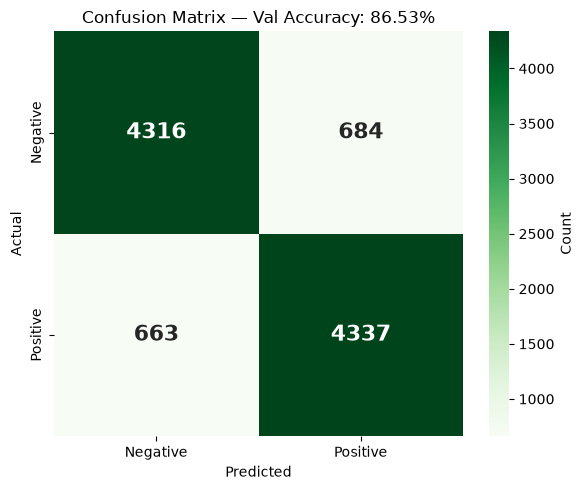

In [28]:
# Build confusion matrix
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar_kws={'label': 'Count'},
            annot_kws={'size': 16, 'weight': 'bold'})
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix — Val Accuracy: {val_acc:.2%}')
plt.tight_layout()
plt.show()

In [29]:
# Pick 5 random validation reviews and show predictions
import random
random.seed(RANDOM_STATE)
sample_idx = random.sample(range(len(X_val)), 5)

for i, idx in enumerate(sample_idx, 1):
    true_label = 'Positive' if y_val[idx] == 1 else 'Negative'
    pred_label = 'Positive' if y_pred[idx] == 1 else 'Negative'
    confidence = y_pred_proba[idx] if y_pred[idx] == 1 else 1 - y_pred_proba[idx]
    status = '✅' if true_label == pred_label else '❌'

    print(f"--- Sample {i} {status} ---")
    print(f"True: {true_label} | Predicted: {pred_label} ({confidence:.2%} confident)")
    print(f"Review snippet: {df['clean_review'][idx][:150]}...")
    print()

--- Sample 1 ❌ ---
True: Positive | Predicted: Negative (67.77% confident)
Review snippet: if you want to see a movie about two utterly unsympathetic characters this is the one the acting is superb both from john cassavetes as the insane par...

--- Sample 2 ✅ ---
True: Negative | Predicted: Negative (71.03% confident)
Review snippet: a great bugs bunny cartoon from the earlier years has bugs as a performer in an window display at a local department store after he s done for the day...

--- Sample 3 ✅ ---
True: Negative | Predicted: Negative (97.03% confident)
Review snippet: i remember this game it was always sitting on the shelves alone until one day i decided to try something new for a change and got this game i stared i...

--- Sample 4 ✅ ---
True: Negative | Predicted: Negative (92.71% confident)
Review snippet: saw this film on dvd yesterday and was gob smacked and flabbergasted the unaffected acting of ddl just blew my mind and i was surprised by the whole c...

--- Sample 5 ✅ -

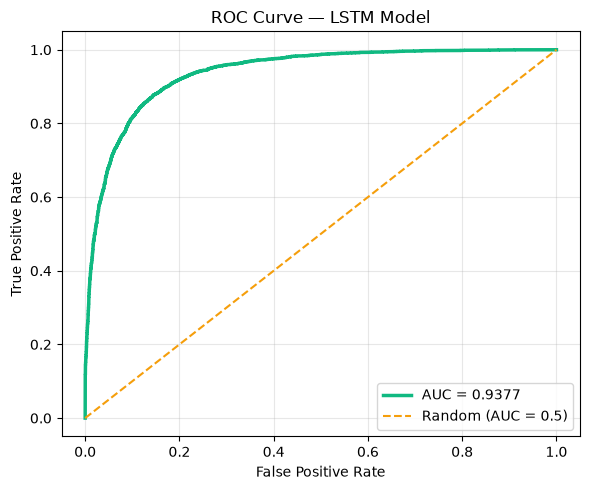

AUC Score: 0.9377


In [30]:
# Compute ROC curve
fpr, tpr, _ = roc_curve(y_val, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#10b981', linewidth=2.5, label=f'AUC = {roc_auc:.4f}')
plt.plot([0, 1], [0, 1], color='#f59e0b', linestyle='--', label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — LSTM Model')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"AUC Score: {roc_auc:.4f}")

<div style="width: 100%; max-width: 900px; box-sizing: border-box; background: linear-gradient(160deg, #0f2e22 0%, #122c1f 100%); border: 1.5px solid #10b981; border-radius: 18px; padding: 30px 24px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; box-shadow: 0 14px 40px rgba(0, 0, 0, 0.8); margin: 20px auto; position: relative; overflow: hidden;">
<div style="position: absolute; top: 0; left: 0; right: 0; height: 4px; background: linear-gradient(90deg, #10b981, #f59e0b, #10b981);"></div>

<!-- Header with app icon -->
<div style="display: flex; align-items: center; gap: 18px; margin-bottom: 24px;">
<div style="flex-shrink: 0; width: 70px; height: 70px; border-radius: 16px; background: linear-gradient(135deg, #10b981, #059669); display: flex; align-items: center; justify-content: center; box-shadow: 0 8px 22px rgba(16, 185, 129, 0.45);">
<svg width="38" height="38" viewBox="0 0 24 24" fill="none" stroke="#ffffff" stroke-width="2" stroke-linecap="round" stroke-linejoin="round">
<path d="M4 7h16M4 12h16M4 17h10"/>
<circle cx="20" cy="17" r="2"/>
</svg>
</div>
<div style="flex: 1;">
<div style="display: inline-block; background: rgba(16, 185, 129, 0.12); border: 1px solid rgba(16, 185, 129, 0.45); border-radius: 20px; padding: 4px 14px; margin-bottom: 8px;">
<span style="color: #6ee7b7; font-size: 11px; font-weight: 800; letter-spacing: 2.5px; text-transform: uppercase;">Project 10 &bull; Part 2 Summary</span>
</div>
<h2 style="color: #ffffff; font-size: 26px; font-weight: 800; letter-spacing: 1px; text-transform: uppercase; margin: 0 0 6px 0;">Natural Language Processing — LSTM</h2>
<p style="color: #f59e0b; font-size: 15px; font-weight: 700; margin: 0 0 4px 0;">IMDB Sentiment Analysis</p>
<p style="color: #94a3b8; font-size: 12.5px; font-weight: 600; margin: 0;">Bidirectional LSTM &bull; TensorFlow / Keras</p>
</div>
</div>

<!-- Stat tiles -->
<div style="display: flex; flex-wrap: wrap; gap: 12px; margin-bottom: 24px;">
<div style="flex: 1 1 170px; background: rgba(15, 46, 34, 0.75); border: 1px solid rgba(16, 185, 129, 0.3); border-radius: 12px; padding: 14px; text-align: center;">
<div style="color: #10b981; font-size: 26px; font-weight: 800;">50K</div>
<div style="color: #94a3b8; font-size: 11px; font-weight: 600; letter-spacing: 1px; text-transform: uppercase;">Reviews</div>
</div>
<div style="flex: 1 1 170px; background: rgba(15, 46, 34, 0.75); border: 1px solid rgba(245, 158, 11, 0.3); border-radius: 12px; padding: 14px; text-align: center;">
<div style="color: #f59e0b; font-size: 26px; font-weight: 800;">2</div>
<div style="color: #94a3b8; font-size: 11px; font-weight: 600; letter-spacing: 1px; text-transform: uppercase;">Classes</div>
</div>
<div style="flex: 1 1 170px; background: rgba(15, 46, 34, 0.75); border: 1px solid rgba(16, 185, 129, 0.3); border-radius: 12px; padding: 14px; text-align: center;">
<div style="color: #10b981; font-size: 26px; font-weight: 800;">86.53%</div>
<div style="color: #94a3b8; font-size: 11px; font-weight: 600; letter-spacing: 1px; text-transform: uppercase;">Val Accuracy</div>
</div>
<div style="flex: 1 1 170px; background: rgba(15, 46, 34, 0.75); border: 1px solid rgba(245, 158, 11, 0.3); border-radius: 12px; padding: 14px; text-align: center;">
<div style="color: #f59e0b; font-size: 26px; font-weight: 800;">90.53%</div>
<div style="color: #94a3b8; font-size: 11px; font-weight: 600; letter-spacing: 1px; text-transform: uppercase;">Train Accuracy</div>
</div>
</div>

<!-- Objective -->
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 14px 16px; margin-bottom: 10px;">
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Objective:</span>
<span style="color: #cbd5e1; font-size: 13.5px; line-height: 1.7;"> Classify movie reviews as positive or negative using an LSTM-based deep learning model, demonstrating sequence modeling for sentiment analysis.</span>
</div>

<!-- Dataset -->
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 14px 16px; margin-bottom: 20px;">
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Dataset:</span>
<span style="color: #cbd5e1; font-size: 13.5px; line-height: 1.7;"> IMDB Movie Reviews (Kaggle) &mdash; 50,000 reviews, balanced across positive and negative sentiment. Split: 40,000 train / 10,000 validation.</span>
</div>

<!-- Pipeline heading -->
<div style="color: #f59e0b; font-size: 13px; font-weight: 800; letter-spacing: 2px; text-transform: uppercase; margin-bottom: 12px;">Pipeline Executed</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">01 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 13.5px;">Text Preprocessing</span>
<span style="color: #cbd5e1; font-size: 12.5px;"> &mdash; HTML/URL removal, lowercase, tokenization (10K vocab), padding to 200 tokens</span>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">02 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 13.5px;">Build LSTM Model</span>
<span style="color: #cbd5e1; font-size: 12.5px;"> &mdash; Embedding (64-d) &rarr; Bidirectional LSTM (64) &rarr; Dense &rarr; Sigmoid</span>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">03 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 13.5px;">Model Training</span>
<span style="color: #cbd5e1; font-size: 12.5px;"> &mdash; 3 epochs (early stopped), patience=2, ModelCheckpoint</span>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 20px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">04 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 13.5px;">Model Evaluation</span>
<span style="color: #cbd5e1; font-size: 12.5px;"> &mdash; Accuracy, loss, classification report, confusion matrix, ROC-AUC</span>
</div>

<!-- Results heading -->
<div style="color: #f59e0b; font-size: 13px; font-weight: 800; letter-spacing: 2px; text-transform: uppercase; margin-bottom: 12px;">Final Results</div>

<div style="display: flex; flex-wrap: wrap; gap: 10px; margin-bottom: 20px;">
<span style="display: inline-block; background: rgba(16, 185, 129, 0.12); color: #6ee7b7; font-size: 12.5px; font-weight: 700; padding: 6px 14px; border-radius: 8px; border: 1px solid rgba(16, 185, 129, 0.4);">Train Acc: 90.53%</span>
<span style="display: inline-block; background: rgba(245, 158, 11, 0.12); color: #fbbf24; font-size: 12.5px; font-weight: 700; padding: 6px 14px; border-radius: 8px; border: 1px solid rgba(245, 158, 11, 0.4);">Val Acc: 86.53%</span>
<span style="display: inline-block; background: rgba(16, 185, 129, 0.12); color: #6ee7b7; font-size: 12.5px; font-weight: 700; padding: 6px 14px; border-radius: 8px; border: 1px solid rgba(16, 185, 129, 0.4);">Val Loss: 0.3205</span>
<span style="display: inline-block; background: rgba(245, 158, 11, 0.12); color: #fbbf24; font-size: 12.5px; font-weight: 700; padding: 6px 14px; border-radius: 8px; border: 1px solid rgba(245, 158, 11, 0.4);">Gap: 4.00%</span>
</div>

<!-- Findings heading -->
<div style="color: #f59e0b; font-size: 13px; font-weight: 800; letter-spacing: 2px; text-transform: uppercase; margin-bottom: 12px;">Key Findings</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #cbd5e1; font-size: 13px; line-height: 1.7;">✅ Bidirectional LSTM captured context from both directions &mdash; crucial when sentiment depends on words appearing after the target word.</span>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #cbd5e1; font-size: 13px; line-height: 1.7;">✅ Embedding layer learned word similarities automatically &mdash; similar words (e.g. "great" and "excellent") clustered close together.</span>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #cbd5e1; font-size: 13px; line-height: 1.7;">✅ Early stopping terminated training at epoch 3 &mdash; capturing the best model before overfitting began.</span>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #cbd5e1; font-size: 13px; line-height: 1.7;">✅ Train&ndash;validation gap of only 4.00% indicates strong generalization on unseen reviews.</span>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 20px;">
<span style="color: #cbd5e1; font-size: 13px; line-height: 1.7;">✅ Balanced dataset (25K positive / 25K negative) &mdash; model showed no bias toward either sentiment class.</span>
</div>

<!-- Classes heading -->
<div style="color: #f59e0b; font-size: 13px; font-weight: 800; letter-spacing: 2px; text-transform: uppercase; margin-bottom: 12px;">Sentiment Classes</div>

<div style="margin-bottom: 20px;">
<span style="display: inline-block; background: rgba(16, 185, 129, 0.12); color: #6ee7b7; font-size: 12.5px; font-weight: 600; padding: 5px 12px; border-radius: 8px; border: 1px solid rgba(16, 185, 129, 0.35); margin: 3px;">Positive Reviews</span>
<span style="display: inline-block; background: rgba(245, 158, 11, 0.12); color: #fbbf24; font-size: 12.5px; font-weight: 600; padding: 5px 12px; border-radius: 8px; border: 1px solid rgba(245, 158, 11, 0.35); margin: 3px;">Negative Reviews</span>
</div>

<!-- Libraries footer -->
<div style="border: 1px dashed rgba(16, 185, 129, 0.5); border-radius: 12px; padding: 14px 18px; text-align: center;">
<div style="color: #10b981; font-size: 12px; font-weight: 800; letter-spacing: 1.5px; text-transform: uppercase; margin-bottom: 8px;">Libraries Used</div>
<div style="color: #cbd5e1; font-size: 13px; line-height: 1.7;">TensorFlow &bull; Keras &bull; NumPy &bull; Pandas &bull; Matplotlib &bull; Seaborn &bull; Scikit-Learn &bull; re</div>
</div>

</div>